In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 80)
pd.options.display.float_format = "{:,.2f}".format

df = pd.read_csv("../data/processed/rumah_clean.csv")

TARGET   = "price_in_rp"
NUMERIK  = ["land_size_m2", "building_size_m2", "bedrooms", "bathrooms", "carports", "garages"]
LOKASI   = "city"
KATEGORI = ["certificate", "property_condition", "furnishing"]
df.shape

(3424, 24)

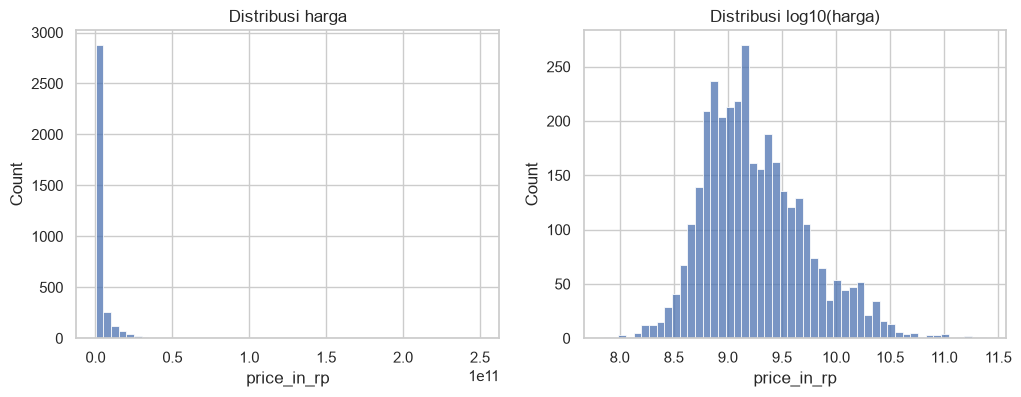

Median: 1500000000.0
Rata-rata: 3921589369.1588783
Skewness: 11.847175122247958 | setelah log: 0.6861690734228713


In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df[TARGET], bins=50, ax=ax[0]);           ax[0].set_title("Distribusi harga")
sns.histplot(np.log10(df[TARGET]), bins=50, ax=ax[1]); ax[1].set_title("Distribusi log10(harga)")
plt.show()

print("Median:", df[TARGET].median())
print("Rata-rata:", df[TARGET].mean())
print("Skewness:", df[TARGET].skew(), "| setelah log:", np.log(df[TARGET]).skew())

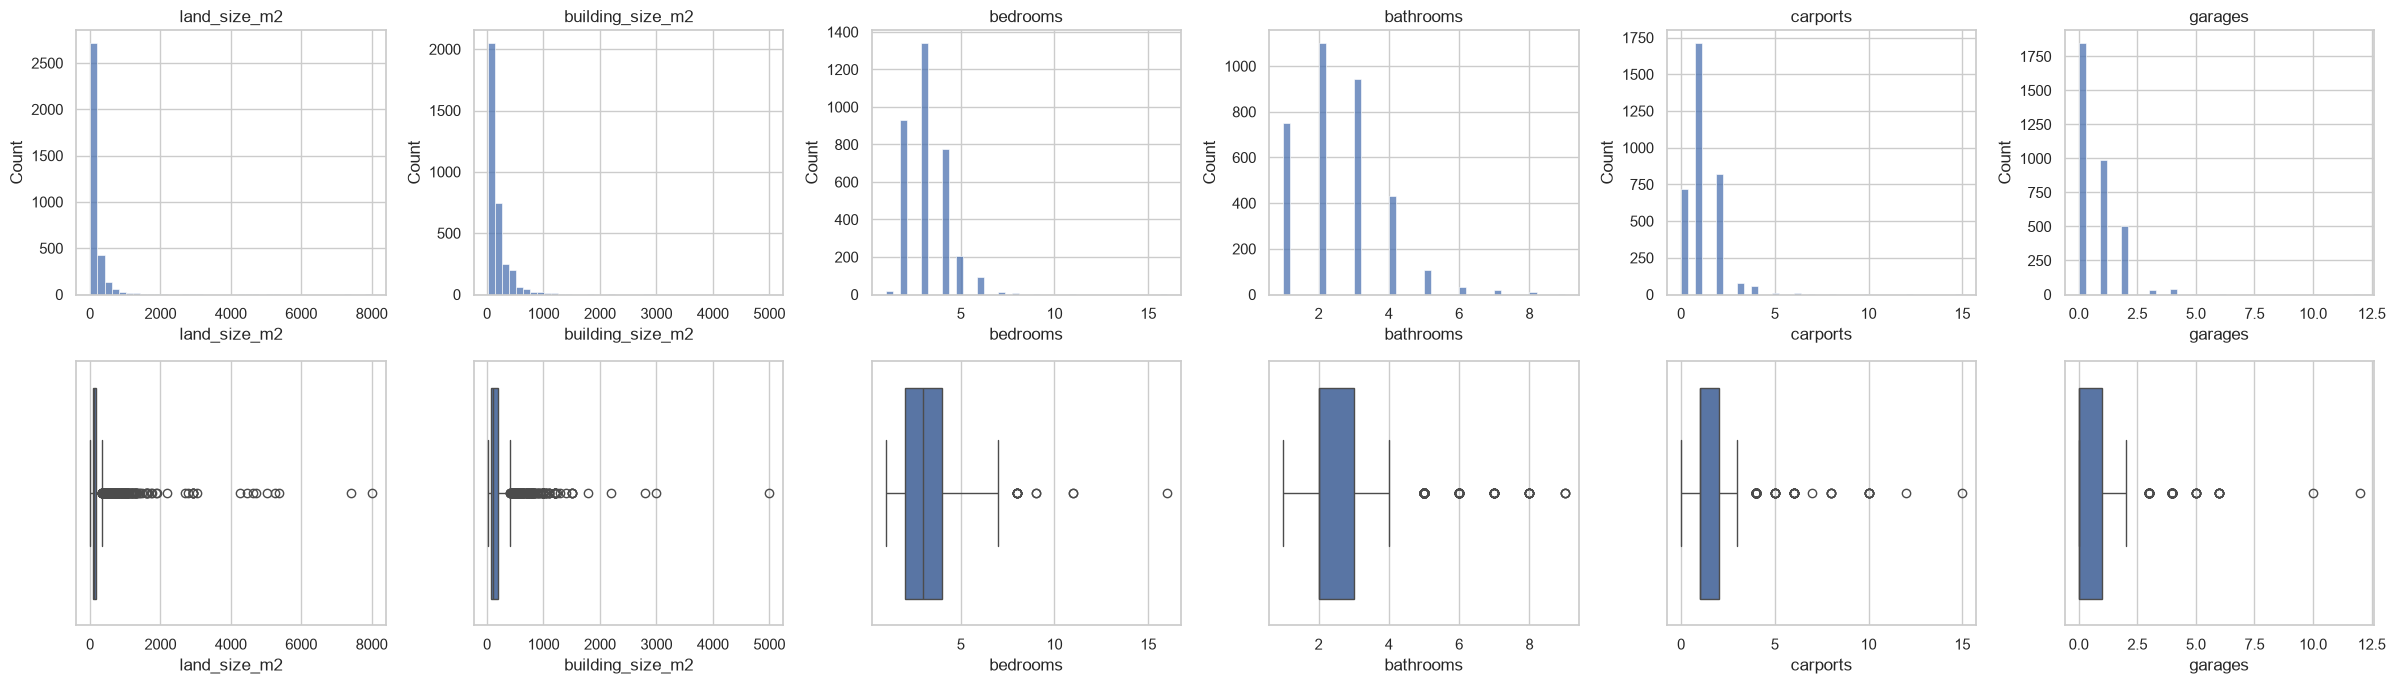

,count,mean,std,min,1%,5%,95%,99%,max
land_size_m2,"3,424.00",194.99,366.24,12.00,30.00,55.00,562.55,"1,298.85","8,000.00"
building_size_m2,"3,424.00",179.90,215.79,19.00,33.00,36.00,519.25,"1,000.00","5,000.00"
bedrooms,"3,393.00",3.19,1.10,1.00,2.00,2.00,5.00,6.00,16.00
bathrooms,"3,398.00",2.49,1.21,1.00,1.00,1.00,4.15,6.00,9.00
carports,"3,424.00",1.19,1.04,0.00,0.00,0.00,2.00,4.00,15.00
garages,"3,424.00",0.68,0.93,0.00,0.00,0.00,2.00,4.00,12.00
price_in_rp,"3,424.00","3,921,589,369.16","9,706,335,766.76","70,000,000.00","225,000,000.00","400,150,000.00","15,000,000,000.00","35,000,000,000.00","250,000,000,000.00"


In [15]:
fig, axes = plt.subplots(2, len(NUMERIK), figsize=(4 * len(NUMERIK), 7))
for i, col in enumerate(NUMERIK):
    sns.histplot(df[col].dropna(), bins=40, ax=axes[0, i]); axes[0, i].set_title(col)
    sns.boxplot(x=df[col], ax=axes[1, i])
plt.tight_layout()
plt.show()

df[NUMERIK + [TARGET]].describe(percentiles=[.01, .05, .95, .99]).T

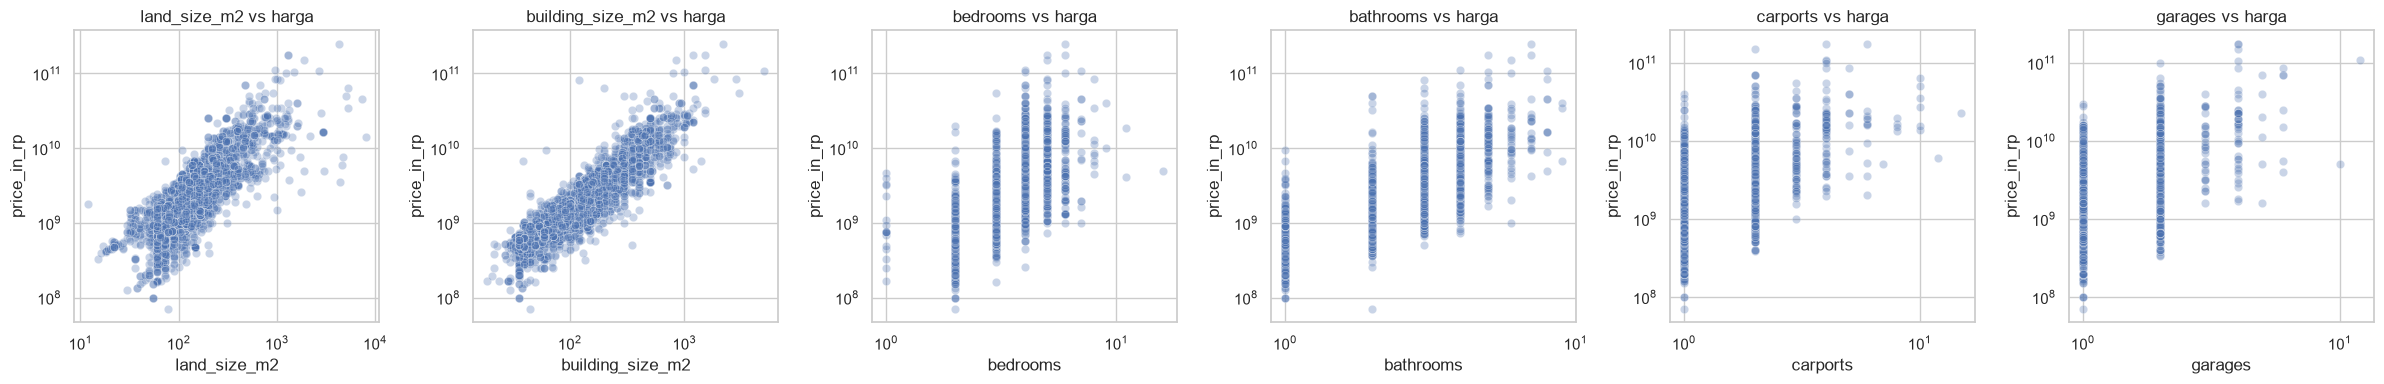

In [16]:
fig, axes = plt.subplots(1, len(NUMERIK), figsize=(4 * len(NUMERIK), 4))
for i, col in enumerate(NUMERIK):
    d = df[df[col] > 0]
    sns.scatterplot(x=d[col], y=d[TARGET], alpha=0.3, ax=axes[i])
    axes[i].set_xscale("log"); axes[i].set_yscale("log")
    axes[i].set_title(f"{col} vs harga")
plt.tight_layout()
plt.show()

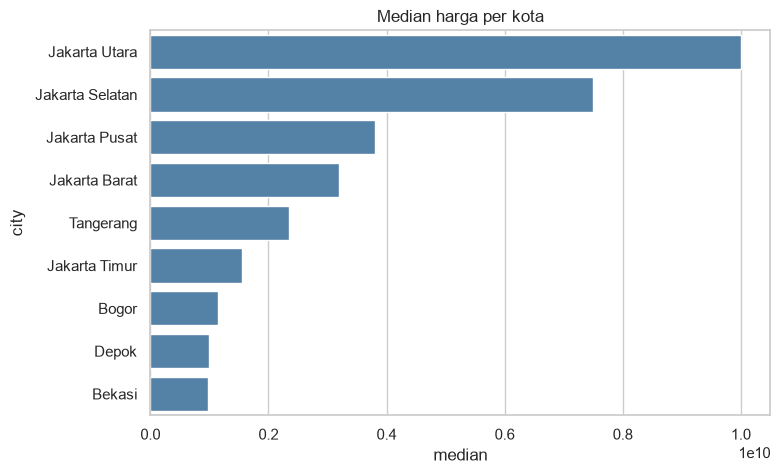

In [17]:
ringkasan = (df.groupby(LOKASI)[TARGET]
               .agg(median="median", jumlah="count")
               .sort_values("median", ascending=False))
ringkasan

plt.figure(figsize=(8, 5))
sns.barplot(x=ringkasan["median"], y=ringkasan.index, color="steelblue")
plt.title("Median harga per kota")
plt.show()

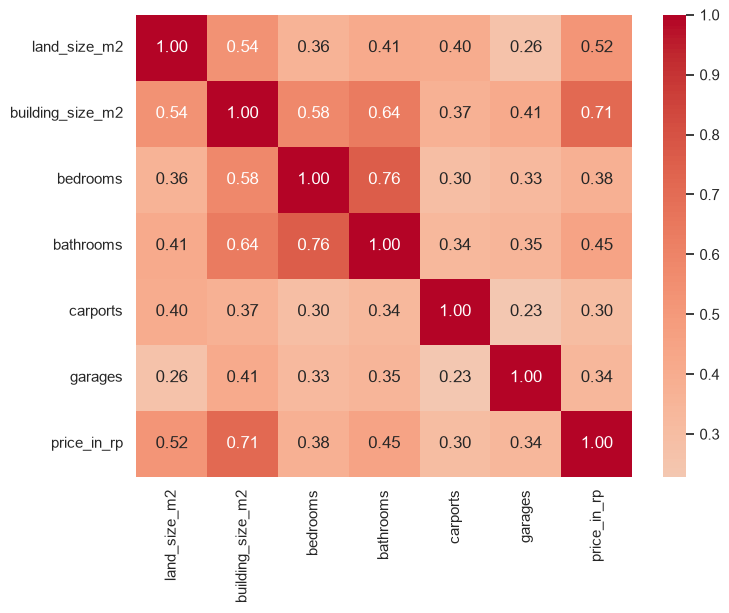

In [18]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[NUMERIK + [TARGET]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.show()

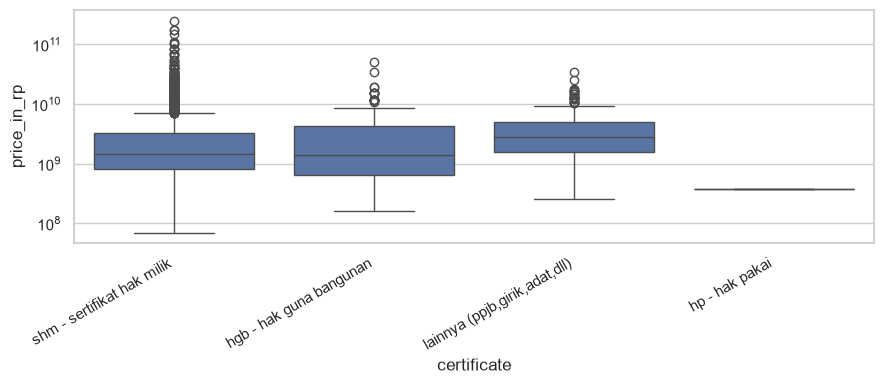

                                        median  count
certificate                                          
lainnya (ppjb,girik,adat,dll) 2,750,000,000.00    195
shm - sertifikat hak milik    1,440,000,000.00   2892
hgb - hak guna bangunan       1,400,000,000.00    199
hp - hak pakai                  375,000,000.00      1


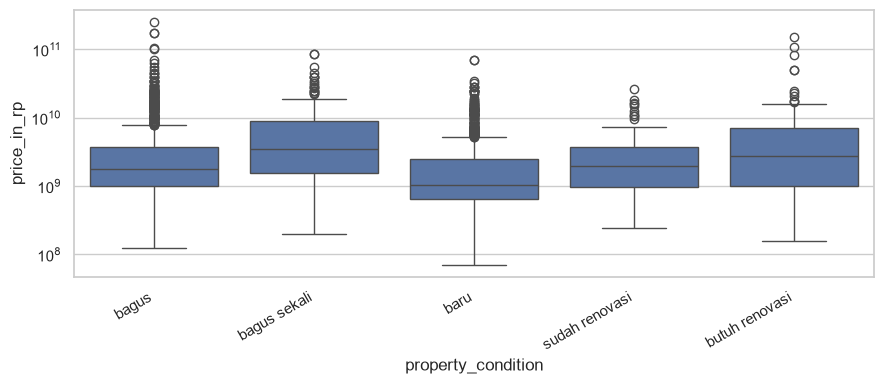

                             median  count
property_condition                        
bagus sekali       3,500,000,000.00    247
butuh renovasi     2,750,000,000.00     89
sudah renovasi     1,970,000,000.00    152
bagus              1,800,000,000.00   1376
baru               1,050,000,000.00   1324


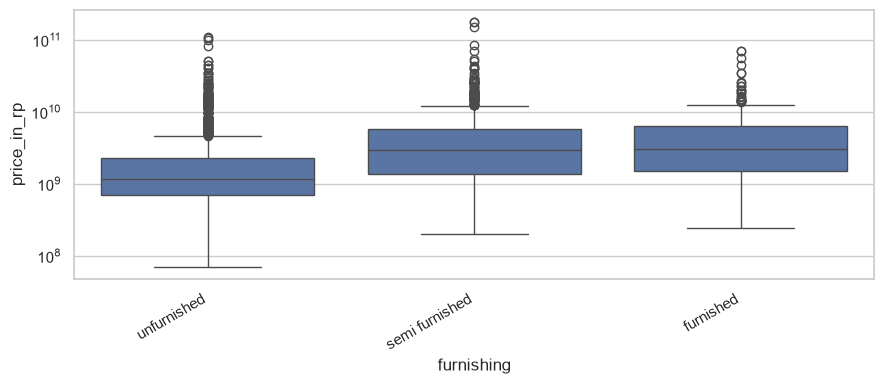

                         median  count
furnishing                            
furnished      3,000,000,000.00    220
semi furnished 2,900,000,000.00    809
unfurnished    1,150,000,000.00   2028


In [19]:
for col in KATEGORI:
    plt.figure(figsize=(9, 4))
    sns.boxplot(data=df, x=col, y=TARGET)
    plt.yscale("log")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()
    print(df.groupby(col)[TARGET].agg(["median", "count"]).sort_values("median", ascending=False))

In [20]:
missing = df.isnull().mean().sort_values(ascending=False) * 100
missing[missing > 0]

building_orientation   45.94
building_age           40.65
furnishing             10.72
property_condition      6.89
certificate             4.00
bedrooms                0.91
bathrooms               0.76
floors                  0.12
ads_id                  0.09
dtype: float64

In [21]:
for col in ["building_age", "building_orientation", "furnishing", "property_condition", "certificate"]:
    print(col)
    print(df.groupby(df[col].isna())[TARGET].agg(["median", "count"]))

building_age
                       median  count
building_age                        
False        1,400,000,000.00   2032
True         1,590,000,000.00   1392
building_orientation
                               median  count
building_orientation                        
False                1,500,000,000.00   1851
True                 1,450,000,000.00   1573
furnishing
                     median  count
furnishing                        
False      1,450,000,000.00   3057
True       2,000,000,000.00    367
property_condition
                             median  count
property_condition                        
False              1,500,000,000.00   3188
True               1,400,000,000.00    236
certificate
                      median  count
certificate                        
False       1,470,000,000.00   3287
True        2,750,000,000.00    137


In [22]:
df.nlargest(8, "land_size_m2")[["title", "city", "price_in_rp", "land_size_m2", "building_size_m2"]]
df[df["carports"] >= 6][["title", "price_in_rp", "carports", "building_size_m2"]]
df[df["garages"] >= 5][["title", "price_in_rp", "garages", "building_size_m2"]]

,title,price_in_rp,garages,building_size_m2
579,Rumah Mewah Dan Elit Lokasi Super Strategis Di Sentul City Bogor,"5,500,000,000.00",6.00,400.00
1327,Jual Cepat Rumah Bagus Untuk Villa di Megamendung,"5,000,000,000.00",10.00,500.00
2108,Dijual rumah mewah katamaran pik brand new lokasi bagus depan taman,"25,000,000,000.00",6.00,750.00
2132,Rumah Luas & Mewah Jakarta Selatan & Sekitarnya,"40,000,000,000.00",5.00,600.00
2233,Rumah di Kemang Jakarta Selatan 950 M2 2 Lantai Kolam Renang SHM,"19,900,000,000.00",5.00,950.00
2305,Rumah Paling Luas Di Pantai Mutiara 3 Lantai Perlu Finishing,"108,000,000,000.00",12.00,"5,000.00"
2326,Rumah American Klasik Sangat Mewah Sekali Full Furnished,"69,000,000,000.00",6.00,"1,200.00"
2327,"Rumah Brand New Menteng 3,5 Lantai Lift Pool Furnish Kotak Dijual 69m","69,000,000,000.00",6.00,"1,200.00"
2434,RUMAH MEWAH SIAP HUNI DEKAT PERKANTORAN DI MAMPANG PRAPATAN,"11,200,000,000.00",5.00,606.00
2477,Rumah ASRI Tanah LUAS akses Jalan BESAR Strategis dkt CILANDAK,"15,000,000,000.00",6.00,450.00
